# Laboratorio 09: Bag of Words, Similitud de Coseno e Índice Invertido
**Base de Datos II, Prof. Heider Sanchez, 2026-2**

Integrantes: Juan Marcos Guerrero Cueva, Adrian Urbina Mendoza y Hector Huaman Puiquin

Antes de ejecutar hay que crear un archivo `.env` junto al notebook con `DB_NAME`, `DB_USER`, `DB_PASSWORD`, `DB_HOST` y `DB_PORT`.
Si la base no existe, el notebook la crea.

## Parte 1: Configuración y carga de datos

In [1]:
import os, re, math, time, warnings
from collections import Counter

import psycopg2, pandas as pd
import matplotlib.pyplot as plt
from psycopg2.extras import Json, execute_batch
from dotenv import load_dotenv
from nltk.stem.snowball import SnowballStemmer

load_dotenv()  # lee las credenciales del archivo .env
warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")
pd.set_option("display.max_colwidth", 80)

def connect_db(dbname=None):
    conn = psycopg2.connect(
        dbname=dbname or os.getenv("DB_NAME"), user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"), host=os.getenv("DB_HOST"), port=os.getenv("DB_PORT")
    )
    return conn

In [2]:
# Crear la base si no existe (CREATE DATABASE necesita autocommit)
conn = connect_db("postgres")
conn.autocommit = True
cur = conn.cursor()
cur.execute("SELECT 1 FROM pg_database WHERE datname = %s", (os.getenv("DB_NAME"),))
if cur.fetchone() is None:
    cur.execute(f'CREATE DATABASE "{os.getenv("DB_NAME")}"')
conn.close()

# Crear las tablas del enunciado
conn = connect_db()
cur = conn.cursor()
cur.execute("""
    CREATE TABLE IF NOT EXISTS noticias (
        id SERIAL PRIMARY KEY,
        url TEXT,
        contenido TEXT,
        categoria VARCHAR(50),
        bag_of_words JSONB
    );
    CREATE TABLE IF NOT EXISTS stopwords (
        id SERIAL PRIMARY KEY,
        word TEXT UNIQUE NOT NULL
    );
""")

# Cargar los datos solo si las tablas están vacías (así no se duplican al re-ejecutar)
cur.execute("SELECT COUNT(*) FROM noticias")
if cur.fetchone()[0] == 0:
    news = pd.read_csv("news_es.csv")  # columnas: url, news, Type
    execute_batch(cur, "INSERT INTO noticias (url, contenido, categoria) VALUES (%s, %s, %s)",
                  news[["url", "news", "Type"]].values.tolist())

cur.execute("SELECT COUNT(*) FROM stopwords")
if cur.fetchone()[0] == 0:
    with open("stoplist.txt", encoding="utf-8") as f:
        words = [line.strip().lower() for line in f if line.strip()]
    execute_batch(cur, "INSERT INTO stopwords (word) VALUES (%s) ON CONFLICT DO NOTHING",
                  [(w,) for w in words])

conn.commit()
cur.execute("SELECT (SELECT COUNT(*) FROM noticias), (SELECT COUNT(*) FROM stopwords)")
print("noticias, stopwords =", cur.fetchone())
conn.close()

noticias, stopwords = (1217, 608)


In [3]:
def fetch_data():
    conn = connect_db()
    df = pd.read_sql("SELECT id, contenido FROM noticias ORDER BY id;", conn)
    conn.close()
    return df

noticias_df = fetch_data()
noticias_df.head()

,id,contenido
0,1,Durante el foro La banca articulador empresarial para el desarrollo sostenib...
1,2,El regulador de valores de China dijo el domingo que buscará una cooperación...
2,3,En una industria históricamente masculina como lo es la aviación Viva presen...
3,4,Con el dato de marzo el IPC interanual encadena su decimoquinta tasa positiv...
4,5,Ayer en Cartagena se dio inicio a la versión número 56 de la Convención Banc...


## Parte 2: Preprocesamiento y Bag of Words
Pasos: minúsculas, tokenización (solo palabras, sin números ni signos), eliminación de stopwords
(leídas de la tabla `stopwords`) y stemming con Snowball para español.
Documentos y consultas pasan por la misma función, así que `economía` y `económico` terminan en el mismo término `econom`.

In [4]:
def load_stopwords():
    conn = connect_db()
    cur = conn.cursor()
    cur.execute("SELECT word FROM stopwords")
    words = {row[0] for row in cur.fetchall()}
    conn.close()
    return words

STOPWORDS = load_stopwords()
stemmer = SnowballStemmer("spanish")

def preprocess(text):
    if not isinstance(text, str):                     # NULL o vacío -> sin términos
        return []
    text = text.lower()                               # 1. minúsculas
    tokens = re.findall(r"[a-záéíóúüñ]+", text)       # 2. tokenización
    tokens = [t for t in tokens if t not in STOPWORDS]  # 3. stopwords
    return [stemmer.stem(t) for t in tokens]          # 4. stemming

def compute_bow(text):
    return dict(Counter(preprocess(text)))            # {término: frecuencia}

print(preprocess("La Economía y el crecimiento económico en 2024!"))
print(compute_bow("Banca digital: la banca y la tecnología financiera"))

['econom', 'crecimient', 'econom']
{'banc': 2, 'digital': 1, 'tecnolog': 1, 'financ': 1}


In [5]:
def update_bow_in_db(dataframe):
    rows = [(Json(compute_bow(text)), doc_id)
            for doc_id, text in zip(dataframe["id"], dataframe["contenido"])]
    conn = connect_db()
    cur = conn.cursor()
    execute_batch(cur, "UPDATE noticias SET bag_of_words = %s WHERE id = %s", rows)
    conn.commit()
    conn.close()
    print("BoW actualizados:", len(rows))

def fetch_data_bow():
    conn = connect_db()
    df = pd.read_sql("SELECT id, contenido, bag_of_words FROM noticias ORDER BY id;", conn)
    conn.close()
    return df

update_bow_in_db(noticias_df)
noticias_bow_df = fetch_data_bow()
noticias_bow_df.head(10)  # primeras 10 filas con su bag of words

BoW actualizados: 1217


,id,contenido,bag_of_words
0,1,Durante el foro La banca articulador empresarial para el desarrollo sostenib...,"{'aca': 1, 'adn': 1, 'cas': 1, 'for': 1, 'ret': 2, 'tem': 2, 'abre': 1, 'ban..."
1,2,El regulador de valores de China dijo el domingo que buscará una cooperación...,"{'dat': 1, 'deb': 1, 'inc': 1, 'med': 1, 'mes': 1, 'not': 1, 'pag': 1, 'par'..."
2,3,En una industria históricamente masculina como lo es la aviación Viva presen...,"{'go': 1, 'us': 3, 'air': 1, 'baj': 1, 'ceo': 2, 'hij': 1, 'low': 2, 'mam': ..."
3,4,Con el dato de marzo el IPC interanual encadena su decimoquinta tasa positiv...,"{'agu': 1, 'car': 2, 'cas': 1, 'dat': 2, 'ine': 2, 'ipc': 7, 'mes': 2, 'sub'..."
4,5,Ayer en Cartagena se dio inicio a la versión número 56 de la Convención Banc...,"{'agu': 1, 'cup': 2, 'deb': 2, 'etc': 1, 'for': 4, 'got': 2, 'jos': 1, 'log'..."
5,6,El emprendimiento del sector inmobiliario Rentatop cerró una ronda de financ...,"{'us': 2, 'big': 1, 'ceo': 1, 'dat': 1, 'sum': 1, 'cerr': 1, 'firm': 1, 'lin..."
6,7,El país tiene pendiente generar más y mejores acciones para contrarrestar la...,"{'ve': 1, 'baj': 1, 'cas': 2, 'dat': 1, 'dej': 1, 'dud': 1, 'med': 1, 'mit':..."
7,8,"En el 'podcast' tenemos el placer de entrevistar a Nacho Escobar, profesor e...","{'agil': 4, 'habl': 1, 'mund': 1, 'nach': 3, 'plac': 1, 'rrhh': 1, 'alumn': ..."
8,9,"El factor humano, normalmente identificado como el factor más débil, ha esta...","{'u': 1, 'ali': 2, 'bas': 1, 'cas': 2, 'cin': 1, 'cuy': 1, 'deb': 1, 'ide': ..."
9,10,"Los perfiles que se demandan en un banco han evolucionado, al igual que lo h...","{'are': 1, 'cab': 1, 'cas': 1, 'dat': 2, 'pud': 1, 'rut': 1, 'sac': 1, 'sal'..."


## Parte 3: Búsqueda booleana, lineal vs. índice invertido
La consulta se convierte en un árbol, por ejemplo `tecnología AND (banca OR finanzas)` → `('AND', 'tecnolog', ('OR', 'banc', 'finanz'))`.
Los operadores se evalúan de izquierda a derecha y los paréntesis agrupan.
Ese mismo árbol lo usan la versión lineal y la versión con índice.

In [6]:
def parse_query(query):
    tokens = query.replace("(", " ( ").replace(")", " ) ").split()
    pos = 0

    def operand():                       # un término o un grupo entre paréntesis
        nonlocal pos
        token = tokens[pos]
        pos += 1
        if token == "(":
            node = expression()
            pos += 1                     # salta el ")"
            return node
        terms = preprocess(token)
        return terms[0] if terms else "" # término normalizado igual que los documentos

    def expression():                    # operando (OPERADOR operando)*
        nonlocal pos
        node = operand()
        while pos < len(tokens) and tokens[pos] != ")":
            op = tokens[pos]
            pos += 1
            node = (op, node, operand())
        return node

    return expression()

parse_query("tecnología AND (banca OR finanzas)")

('AND', 'tecnolog', ('OR', 'banc', 'finanz'))

### 3.1 Búsqueda lineal
Recorre todos los documentos y revisa si el BoW de cada uno cumple la consulta.

In [7]:
def matches(node, bow):
    if isinstance(node, str):            # hoja: ¿el término está en el documento?
        return node in bow
    op, left, right = node
    a, b = matches(left, bow), matches(right, bow)
    if op == "AND":
        return a and b
    if op == "OR":
        return a or b
    if op == "AND-NOT":
        return a and not b
    raise ValueError(f"Operador desconocido: {op}")

def boolean_search_linear(query, dataframe):
    tree = parse_query(query)
    return [doc_id for doc_id, bow in zip(dataframe["id"], dataframe["bag_of_words"])
            if matches(tree, bow)]

for q in ["economía AND inflación", "banca OR finanzas", "tecnología AND-NOT inflación"]:
    result = boolean_search_linear(q, noticias_bow_df)
    print(f"{q:32} -> {len(result)} documentos, primeros: {result[:8]}")

economía AND inflación           -> 244 documentos, primeros: [5, 7, 18, 21, 24, 32, 33, 34]
banca OR finanzas                -> 547 documentos, primeros: [1, 2, 5, 9, 10, 12, 13, 15]
tecnología AND-NOT inflación     -> 306 documentos, primeros: [12, 13, 14, 15, 16, 17, 19, 20]


### 3.2 Búsqueda con índice invertido
- `index[término]` = lista de `(doc_id, tf)` ordenada por id.
- `idf[término]` = log10(N / df).
- `length[doc]` = norma del vector TF-IDF del documento, con peso `w = log10(1 + tf) · idf`.

`compute_idf_and_length` calcula idf y normas directamente desde los BoW. La usan tanto la construcción del índice
como el coseno lineal (Parte 4), así que las dos versiones aplican exactamente la misma fórmula.

In [8]:
def tf_weight(tf):
    return math.log10(1 + tf)

def compute_idf_and_length(bows):        # bows = {doc_id: {término: tf}}
    N = len(bows)
    df = Counter()
    for bow in bows.values():
        df.update(bow.keys())            # en cuántos documentos aparece cada término
    idf = {term: math.log10(N / n) for term, n in df.items()}
    length = {doc_id: math.sqrt(sum((tf_weight(tf) * idf[t]) ** 2 for t, tf in bow.items()))
              for doc_id, bow in bows.items()}
    return idf, length

class InvertedIndex:
    def __init__(self):
        self.index = {}
        self.idf = {}
        self.length = {}
        self._docs = {}
        self._bow = {}

    def build_from_db(self):
        conn = connect_db()
        cur = conn.cursor()
        cur.execute("SELECT id, contenido, bag_of_words FROM noticias ORDER BY id")
        rows = cur.fetchall()
        conn.close()
        self.build(rows)

    def build(self, rows):               # rows = [(id, contenido, bow), ...]
        self.__init__()
        for doc_id, contenido, bow in rows:
            self._docs[doc_id] = contenido
            self._bow[doc_id] = bow
            for term, tf in bow.items():
                self.index.setdefault(term, []).append((doc_id, tf))
        self.idf, self.length = compute_idf_and_length(self._bow)

    def L(self, word):                   # la palabra se normaliza igual que los documentos
        terms = preprocess(word)
        return self.index.get(terms[0], []) if terms else []

    def showDocument(self, doc_id, max_chars=80):
        return self._docs.get(doc_id, "")[:max_chars] + "..."

    def showDocuments(self, posting_list, max_chars=80):
        return [self.showDocument(doc_id, max_chars) for doc_id, *_ in posting_list]

    def boolean_search(self, query):     # misma consulta en texto, resuelta con el índice
        def evaluate(node):
            if isinstance(node, str):
                return self.index.get(node, [])
            op, left, right = node
            return OPERATIONS[op](evaluate(left), evaluate(right))
        return [doc_id for doc_id, _ in evaluate(parse_query(query))]

def AND(list1, list2):                   # documentos que están en ambas listas
    docs2 = {doc_id for doc_id, _ in list2}
    return [(doc_id, tf) for doc_id, tf in list1 if doc_id in docs2]

def OR(list1, list2):                    # unión, ordenada por doc_id
    union = dict(list2)
    union.update(dict(list1))
    return sorted(union.items())

def AND_NOT(list1, list2):               # documentos de list1 que no están en list2
    docs2 = {doc_id for doc_id, _ in list2}
    return [(doc_id, tf) for doc_id, tf in list1 if doc_id not in docs2]

OPERATIONS = {"AND": AND, "OR": OR, "AND-NOT": AND_NOT}

idx = InvertedIndex()
idx.build_from_db()
print("documentos:", len(idx._docs), "| términos:", len(idx.index),
      "| postings:", sum(len(p) for p in idx.index.values()))

documentos: 1217 | términos: 13330 | postings: 180214


#### Pruebas (las 3 del enunciado + 3 nuevas)

In [9]:
print(idx.showDocuments(AND(idx.L("sostenibilidad"), AND(idx.L("ambiente"), idx.L("renovables")))))
print(idx.showDocuments(AND(idx.L("tecnología"), OR(idx.L("banca"), idx.L("finanzas"))))[:3])
print(idx.showDocuments(AND_NOT(idx.L("economía"), idx.L("inflación")))[:3])
# 3 pruebas nuevas
print(idx.showDocuments(AND_NOT(OR(idx.L("banca"), idx.L("finanzas")), idx.L("inflación")))[:3])
print(idx.showDocuments(AND(idx.L("economía"), OR(idx.L("tecnología"), idx.L("sostenibilidad"))))[:3])
print(idx.showDocuments(AND_NOT(OR(idx.L("renovables"), idx.L("ambiente")), idx.L("economía")))[:3])

['La importancia que cada día más empresas le otorgan al tema de la sostenibilidad...', 'Esta tipología de energía, clave para la sostenibilidad del planeta, nace de la ...', 'El turismo sostenible persigue desarrollar su actividad generando un impacto mín...', 'En un intento por aumentar el acceso al financiamiento climático, IFC otorgó un ...', 'Este jueves se conoció que IFC otorgó un préstamo de hasta US200 millones a Bbva...', 'Fue en 1972, con la Conferencia de Estocolmo, cuando se hizo visible la concienc...', "Un 'green loan' o préstamo verde’ es una fórmula para financiar un proyecto o em...", 'Según el último informe de la Superintendencia Financiera de Colombia SFC Bbva e...', 'Una empresa no es solo lo que vende, también es lo que compra. Si de verdad quie...']
['BBVA ha presentado BBVA Spark, su propuesta integral de servicios financieros pa...', 'Con acciones que se comprometen con el desarrollo sostenible, ambas organizacion...', 'El regulador bancario de China dijo que 

In [10]:
# Comprobación: lineal e índice deben devolver exactamente los mismos documentos
BOOLEAN_QUERIES = [
    "economía AND inflación",
    "banca OR finanzas",
    "tecnología AND-NOT inflación",
    "sostenibilidad AND ambiente AND renovables",
    "tecnología AND (banca OR finanzas)",
    "economía AND-NOT inflación",
    "(banca OR finanzas) AND-NOT inflación",            # nueva
    "economía AND (tecnología OR sostenibilidad)",      # nueva
    "(renovables OR ambiente) AND-NOT economía",        # nueva
]
rows = []
for q in BOOLEAN_QUERIES:
    linear = boolean_search_linear(q, noticias_bow_df)
    indexed = idx.boolean_search(q)
    assert linear == indexed, q
    rows.append({"consulta": q, "resultados": len(linear), "iguales": linear == indexed})
boolean_results = pd.DataFrame(rows)
boolean_results

,consulta,resultados,iguales
0,economía AND inflación,244,True
1,banca OR finanzas,547,True
2,tecnología AND-NOT inflación,306,True
3,sostenibilidad AND ambiente AND renovables,9,True
4,tecnología AND (banca OR finanzas),174,True
5,economía AND-NOT inflación,358,True
6,(banca OR finanzas) AND-NOT inflación,368,True
7,economía AND (tecnología OR sostenibilidad),212,True
8,(renovables OR ambiente) AND-NOT economía,65,True


## Parte 4: Similitud de coseno, lineal vs. índice invertido
- **Lineal:** calcula df, idf y las normas recorriendo **todos** los BoW en cada consulta (no usa `index`, `idf` ni `length`), y luego el coseno contra cada documento.
- **Índice:** usa `idf` y `length` ya precalculados y solo puntúa los documentos que aparecen en las listas de los términos de la consulta.

Si hay empate en el score, se ordena por `doc_id` para que las dos versiones devuelvan el mismo orden.

In [11]:
def query_vector(query, idf):
    q_tf = Counter(preprocess(query))
    return {t: tf_weight(tf) * idf[t] for t, tf in q_tf.items() if idf.get(t, 0) > 0}

def top_k_scores(score, top_k):
    return sorted(score.items(), key=lambda t: (-t[1], t[0]))[:top_k]

def cosine_search_linear(self, query, top_k=5):
    idf, length = compute_idf_and_length(self._bow)    # TF-IDF desde cero, sin el índice
    q = query_vector(query, idf)
    q_norm = math.sqrt(sum(w * w for w in q.values()))
    score = {}
    for doc_id, bow in self._bow.items():               # todos los documentos
        dot = sum(w_q * tf_weight(bow[t]) * idf[t] for t, w_q in q.items() if t in bow)
        if dot > 0:
            score[doc_id] = dot / (q_norm * length[doc_id])
    return top_k_scores(score, top_k)

InvertedIndex.cosine_search_linear = cosine_search_linear

In [12]:
def cosine_search(self, query, top_k=5):
    q = query_vector(query, self.idf)
    q_norm = math.sqrt(sum(w * w for w in q.values()))
    score = {}
    for term, w_q in q.items():                         # solo los términos de la consulta
        for doc_id, tf in self.index[term]:             # solo documentos candidatos
            score[doc_id] = score.get(doc_id, 0) + w_q * tf_weight(tf) * self.idf[term]
    for doc_id in score:
        score[doc_id] /= q_norm * self.length[doc_id]
    return top_k_scores(score, top_k)

InvertedIndex.cosine_search = cosine_search

In [13]:
COSINE_QUERIES = [
    "innovaciones en banca digital y tecnología financiera",
    "inflación y crecimiento económico",
    "sostenibilidad y energías renovables",
]
for q in COSINE_QUERIES:
    linear, indexed = idx.cosine_search_linear(q, 5), idx.cosine_search(q, 5)
    print(f"\n{q}")
    print("Lineal :", [(d, round(s, 6)) for d, s in linear])
    print("Índice :", [(d, round(s, 6)) for d, s in indexed])
    same_ids = [d for d, _ in linear] == [d for d, _ in indexed]
    max_diff = max(abs(a[1] - b[1]) for a, b in zip(linear, indexed))
    print(f"Mismos documentos: {same_ids} | diferencia máxima de score: {max_diff:.1e}")
    assert same_ids and max_diff < 1e-12


innovaciones en banca digital y tecnología financiera
Lineal : [(390, 0.188713), (1097, 0.178394), (829, 0.173212), (282, 0.163256), (220, 0.16101)]
Índice : [(390, 0.188713), (1097, 0.178394), (829, 0.173212), (282, 0.163256), (220, 0.16101)]
Mismos documentos: True | diferencia máxima de score: 0.0e+00



inflación y crecimiento económico
Lineal : [(96, 0.140239), (143, 0.140239), (1214, 0.130668), (783, 0.127053), (198, 0.126491)]
Índice : [(96, 0.140239), (143, 0.140239), (1214, 0.130668), (783, 0.127053), (198, 0.126491)]
Mismos documentos: True | diferencia máxima de score: 2.8e-17



sostenibilidad y energías renovables
Lineal : [(661, 0.264492), (620, 0.168115), (150, 0.164233), (189, 0.144465), (713, 0.144465)]
Índice : [(661, 0.264492), (620, 0.168115), (150, 0.164233), (189, 0.144465), (713, 0.144465)]
Mismos documentos: True | diferencia máxima de score: 2.8e-17


#### Pruebas con datos pequeños (resultado conocido a mano)
Cuatro documentos de juguete para revisar los casos borde: término inexistente, texto vacío, `top_k` mayor que la cantidad de resultados
y un término que aparece en todos los documentos (idf = 0).

In [14]:
toy = [(1, "", {"banc": 2, "digital": 1}),
       (2, "", {"banc": 1, "inflacion": 1}),
       (3, "", {"tecnolog": 1, "digital": 1}),
       (4, "", {})]
toy_df = pd.DataFrame(toy, columns=["id", "contenido", "bag_of_words"])
t = InvertedIndex()
t.build(toy)

assert t.boolean_search("banca AND digital") == [1]
assert t.boolean_search("banca OR tecnología") == [1, 2, 3]
assert t.boolean_search("banca AND-NOT inflación") == [1]
assert t.boolean_search("digital AND (banca OR tecnología)") == [1, 3]
assert t.boolean_search("palabrainexistente") == []
for q in ["banca AND digital", "banca OR tecnología", "digital AND (banca OR tecnología)"]:
    assert boolean_search_linear(q, toy_df) == t.boolean_search(q)

assert t.cosine_search("palabrainexistente") == [] == t.cosine_search_linear("palabrainexistente")
assert t.cosine_search("") == [] == t.cosine_search_linear("")
assert [d for d, _ in t.cosine_search("banca digital", 10)] == [1, 2, 3]   # top_k > resultados
assert t.cosine_search("banca digital", 10) == t.cosine_search_linear("banca digital", 10)
assert t.cosine_search("banca", 1)[0][0] == 1                               # tf=2 gana a tf=1

t.build([(1, "", {"a": 1}), (2, "", {"a": 3})])                            # "a" está en todos: idf = 0
assert t.idf["a"] == 0 and t.cosine_search("a") == []
print("Todas las pruebas pasaron")

Todas las pruebas pasaron


## Parte 5: Experimento, medición de tiempos
- **Colecciones:** los primeros N documentos por `id`, con N ∈ {10, 100, 250, 500, 750, 1000, 1217}. Cada tamaño tiene su propio índice, construido sobre el mismo subconjunto que recorre la versión lineal.
- **Consultas:** las 9 booleanas y las 3 de coseno de arriba. Se ejecutan una vez para calentar y luego se miden **30 repeticiones** de cada una con `time.perf_counter()`.
- **Qué se mide:** el tiempo de consulta. La construcción del índice se mide aparte (promedio de 5 construcciones).
- Antes de medir se comprueba que, en cada tamaño, lineal e índice devuelven lo mismo.

In [15]:
SIZES = [10, 100, 250, 500, 750, 1000, 1217]
REPEATS = 30

def avg_time(function, queries, repeats=REPEATS):
    for q in queries:                    # calentamiento, no se mide
        function(q)
    times = []
    for _ in range(repeats):
        for q in queries:
            start = time.perf_counter()
            function(q)
            times.append(time.perf_counter() - start)
    return sum(times) / len(times)

records = []
for n in SIZES:
    subset_df = noticias_bow_df.iloc[:n]
    subset_rows = list(zip(subset_df["id"], subset_df["contenido"], subset_df["bag_of_words"]))

    build_times = []
    for _ in range(5):
        start = time.perf_counter()
        sub_idx = InvertedIndex()
        sub_idx.build(subset_rows)
        build_times.append(time.perf_counter() - start)

    for q in BOOLEAN_QUERIES:             # mismo resultado en este tamaño
        assert boolean_search_linear(q, subset_df) == sub_idx.boolean_search(q)
    for q in COSINE_QUERIES:
        a, b = sub_idx.cosine_search_linear(q), sub_idx.cosine_search(q)
        assert [d for d, _ in a] == [d for d, _ in b]

    records.append({
        "N": n,
        "bool_lineal": avg_time(lambda q: boolean_search_linear(q, subset_df), BOOLEAN_QUERIES),
        "bool_indice": avg_time(sub_idx.boolean_search, BOOLEAN_QUERIES),
        "cos_lineal": avg_time(sub_idx.cosine_search_linear, COSINE_QUERIES),
        "cos_indice": avg_time(sub_idx.cosine_search, COSINE_QUERIES),
        "construccion": sum(build_times) / len(build_times),
    })
    print(f"N={n} listo")

results = pd.DataFrame(records)
os.makedirs("resultados", exist_ok=True)
results.to_csv("resultados/tiempos.csv", index=False)
results

N=10 listo


N=100 listo


N=250 listo


N=500 listo


N=750 listo


N=1000 listo


N=1217 listo


,N,bool_lineal,bool_indice,cos_lineal,cos_indice,construccion
0,10,0.000117,0.000036,0.000734,0.000047,0.000865
1,100,0.000195,0.000044,0.006646,0.000096,0.010964
2,250,0.000311,0.000057,0.016612,0.000167,0.027359
3,500,0.000517,0.000075,0.032517,0.000310,0.072992
4,750,0.000737,0.000103,0.048272,0.000454,0.102433
5,1000,0.000961,0.000124,0.063357,0.000580,0.127602
6,1217,0.001209,0.000149,0.077862,0.000712,0.152287


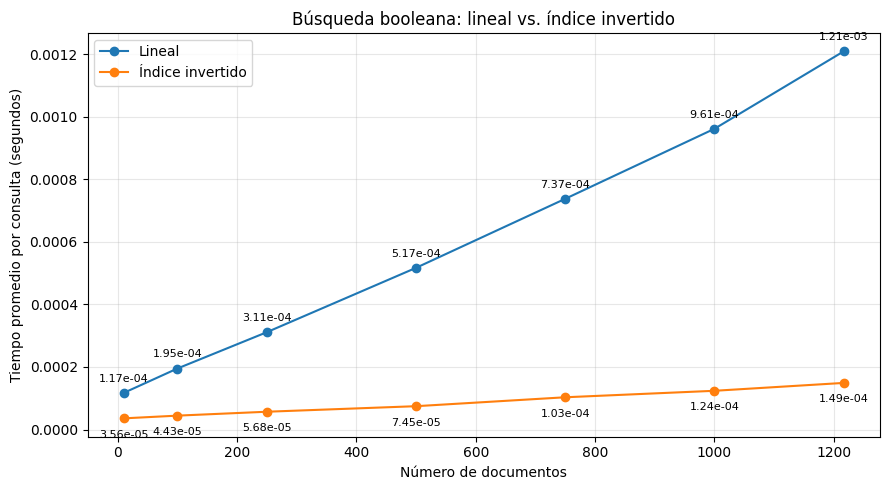

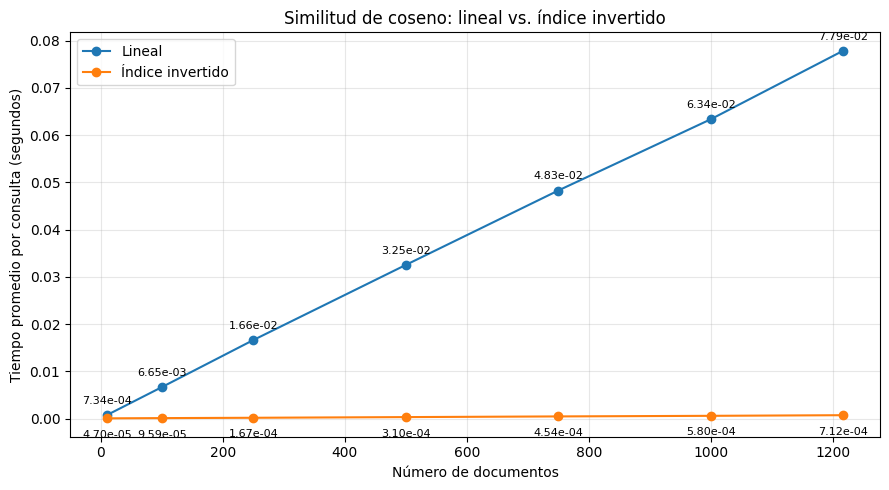

In [16]:
def plot(linear_col, index_col, title, filename):
    fig, ax = plt.subplots(figsize=(9, 5))
    for col, label, offset in [(linear_col, "Lineal", 8), (index_col, "Índice invertido", -14)]:
        ax.plot(results["N"], results[col], marker="o", label=label)
        for x, y in zip(results["N"], results[col]):
            ax.annotate(f"{y:.2e}", (x, y), xytext=(0, offset), textcoords="offset points",
                        ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Número de documentos")
    ax.set_ylabel("Tiempo promedio por consulta (segundos)")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"resultados/{filename}", dpi=150)
    plt.show()

plot("bool_lineal", "bool_indice", "Búsqueda booleana: lineal vs. índice invertido", "booleana.png")
plot("cos_lineal", "cos_indice", "Similitud de coseno: lineal vs. índice invertido", "coseno.png")

In [17]:
# Datos de apoyo para el análisis
summary = results.copy()
summary["speedup_bool"] = summary["bool_lineal"] / summary["bool_indice"]
summary["speedup_cos"] = summary["cos_lineal"] / summary["cos_indice"]
# ¿cuántas consultas hacen falta para que construir el índice valga la pena?
summary["consultas_amortizar_bool"] = summary["construccion"] / (summary["bool_lineal"] - summary["bool_indice"])
summary["consultas_amortizar_cos"] = summary["construccion"] / (summary["cos_lineal"] - summary["cos_indice"])
summary.round(6)

,N,bool_lineal,bool_indice,cos_lineal,cos_indice,construccion,speedup_bool,speedup_cos,consultas_amortizar_bool,consultas_amortizar_cos
0,10,0.000117,0.000036,0.000734,0.000047,0.000865,3.276963,15.617213,10.664777,1.260112
1,100,0.000195,0.000044,0.006646,0.000096,0.010964,4.394993,69.320644,72.862225,1.673867
2,250,0.000311,0.000057,0.016612,0.000167,0.027359,5.473460,99.731113,107.637103,1.663617
3,500,0.000517,0.000075,0.032517,0.000310,0.072992,6.931376,104.956229,165.081766,2.266300
4,750,0.000737,0.000103,0.048272,0.000454,0.102433,7.155457,106.350127,161.497404,2.142136
5,1000,0.000961,0.000124,0.063357,0.000580,0.127602,7.766362,109.222336,152.393471,2.032618
6,1217,0.001209,0.000149,0.077862,0.000712,0.152287,8.116232,109.335679,143.657488,1.973914


## Parte 6: Análisis de resultados

**1. Complejidad.** La booleana lineal es O(N·q), porque revisa el BoW de cada documento. La booleana con índice es O(Σ|L(t)|), porque solo recorre las listas de los términos consultados. El coseno lineal es O(P), donde P es el total de pares (término, documento), ya que en cada consulta recalcula df, idf y normas. El coseno con índice es O(Σ|L(t)| + C·log C), donde C es el número de candidatos. Los datos lo confirman. De N=10 a N=1217 (122 veces más documentos), el coseno lineal crece 106 veces (de 0.00073 s a 0.0779 s), casi proporcional a N. La booleana lineal crece 10 veces (de 0.00012 s a 0.00121 s), porque con N pequeño pesa el costo fijo de analizar la consulta. Con índice el crecimiento es mucho menor: 4 veces en booleana y 15 en coseno.

**2. Punto de quiebre.** En tiempo de consulta, el índice gana desde el tamaño más pequeño medido (N=10) en ambos casos: 3.3 veces más rápido en booleana y 15.6 en coseno, así que los puntos coinciden. Si se suma la construcción, ya no coinciden. En coseno, el índice se paga con unas 2 consultas. En booleana hacen falta entre 11 consultas (N=10) y 144 (N=1217).

**3. Overhead.** Sí: la construcción del índice. Toma 0.87 ms con N=10 y 152 ms con N=1217, más que una búsqueda booleana lineal (0.12 ms y 1.21 ms). Ese tiempo se va en recorrer todos los BoW, armar las listas y calcular idf y normas. Con pocas consultas booleanas, el índice no conviene.

**4. Exactitud.** Las 9 consultas booleanas devolvieron los mismos IDs con ambos enfoques en los 7 tamaños. En coseno coinciden el top-5 y su orden. La diferencia máxima de score es 2.8e-17, porque las sumas en coma flotante se hacen en distinto orden: el índice suma por término y el lineal por documento. Los empates (por ejemplo, los documentos 96 y 143) se resuelven por id.

**5. Limitaciones.** Hoy el índice tiene 13 330 términos y 180 214 postings. Con 100 veces más noticias tendría unos 18 millones de postings en tuplas de Python, es decir, varios GB de RAM. Además, habría que reconstruirlo en cada ejecución, y eso pasaría de 0.15 s a decenas de segundos. La alternativa es un índice persistente en disco: una tabla de PostgreSQL `(termino, doc_id, tf)` con índice B+Tree sobre `termino`, o un índice GIN sobre `tsvector`. Así solo se leen las listas que la consulta necesita.